# Exercise 6
Nico Reiterer - 5191 2112

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 6.1

Exact integral of $f(x) = \int_{-\infty}^\infty e^{-x^2}sin^2(x)$:

$$ sin^2(x) = \frac{1 - cos(2x)}{2} $$

$$ \int_{-\infty}^\infty e^{-x^2}sin^2(x) = \frac{1}{2}\int_{-\infty}^\infty e^{-x^2} - \frac{1}{2}\int_{-\infty}^\infty e^{-x^2}cos(2x) $$

Gauß'sche integral: $$ \int_{-\infty}^\infty e^{-x^2} = \sqrt{\pi} $$
Gauß Cosine Integral: $$ \int_{-\infty}^\infty e^{-x^2}cos(2x) = \sqrt{\pi} e^{-1} $$

Toether, we have:
$$ \int_{-\infty}^\infty e^{-x^2}sin^2(x) = \frac{\sqrt{\pi}}{2} - \frac{\sqrt{\pi}}{2} e^{-1} = \frac{\sqrt{\pi}}{2}(1 - e^{-1}) $$

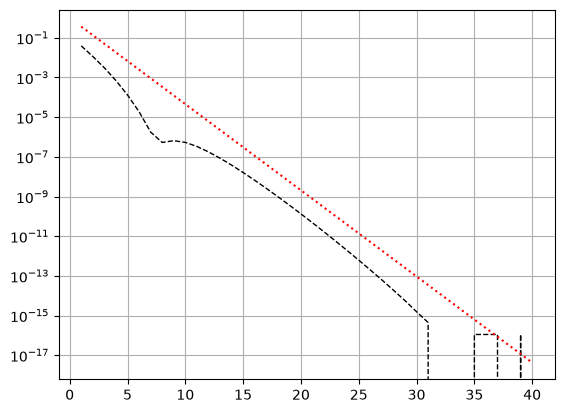

In [26]:
N = np.arange(1,41)
f = lambda x: np.exp(-x**2) * np.sin(x)**2
F = np.sqrt(np.pi) / 2 * (1 - np.exp(-1))

def simple_trapezoidal(f: callable, N: int):
    h = 1 / np.sqrt(N)
    x = np.arange(-N, N + 1) * h
    return h * np.sum(f(x))

error = np.zeros(len(N))
for i, n in enumerate(N):
    error[i] = np.abs(F - simple_trapezoidal(f=f, N=n))

plt.semilogy(N, error,"k--", lw=1,)
plt.semilogy(N, np.exp(-N), "r:", label=r"$e^{-N}$")
plt.grid(True)


## 6.2

An affine change is necessary to map the interval $[0, 1]$ to $[-1, 1]$:
$$ x = \frac{a + b}{2} + \frac{b - a}{2}t $$

$$ \int_0^1 f(x) dx \approx \frac{b - a}{2} \sum_i w_i f\left(\frac{a + b}{2} + \frac{b - a}{2}t_i\right)$$

In [62]:
def affine_sum(f, weights, a, b, x):
    return (b - a) / 2 * np.sum(weights*f((a + b)/2 + (b - a)/2 * x))

def composite_gauss(f, n, L, q):
    """ Composite Gauss rule for integration over (0, 1) """
    # Computes the sample points and weights for Gauss-Legendre quadrature. These sample points and weights will 
    # correctly integrate polynomials of degree 2*deg - 1 or less over the interval [-1, 1] with the weight function f(x) = 1.
    x, w = np.polynomial.legendre.leggauss(deg=n) 

    # (0,qL−1),(qL−1,qL−2),(qL−2,qL−3)··· ,(q,1)
    qs = q**np.arange(L-1, -1, -1) # e.g. for q = 2 and L = 10: [512, 254, ..., 1]

    total = 0
    total += affine_sum(f, w, 0, q**(L-1), x) # doing the (0, q**L-1)
    for a, b in zip(qs[:-1], qs[1:]):
        total += affine_sum(f, w, a, b, x)
    return total

In [63]:
from itertools import product

m = [0, 1, 2]

# just some random combination
ns = [1, 2, 3, 5]
Ls = [1, 2, 5, 10]
qs_test = [0.5, 0.15]

# (name, function, exact value of integral)
tests = [(f"x^{mm}", (lambda x, mm=mm: x**mm), 1 / (mm + 1)) for mm in m]
tests.append(("exp(x)", lambda x: np.exp(x), np.e - 1))

for n in ns:
    print(f"\n=== n = {n} (exact for degree <= {2*n - 1}) ===")
    print(f"{'f':>8} {'L':>3} {'q':>5} {'error':>12}")
    for (name, f, exact), L, q in product(tests, Ls, qs_test):
        err = abs(composite_gauss(f, n, L, q) - exact)
        print(f"{name:>8} {L:>3} {q:>5} {err:12.2e}")


=== n = 1 (exact for degree <= 1) ===
       f   L     q        error
     x^0   1   0.5     0.00e+00
     x^0   1  0.15     0.00e+00
     x^0   2   0.5     0.00e+00
     x^0   2  0.15     0.00e+00
     x^0   5   0.5     0.00e+00
     x^0   5  0.15     0.00e+00
     x^0  10   0.5     0.00e+00
     x^0  10  0.15     0.00e+00
     x^1   1   0.5     0.00e+00
     x^1   1  0.15     0.00e+00
     x^1   2   0.5     0.00e+00
     x^1   2  0.15     5.55e-17
     x^1   5   0.5     0.00e+00
     x^1   5  0.15     5.55e-17
     x^1  10   0.5     0.00e+00
     x^1  10  0.15     5.55e-17
     x^2   1   0.5     8.33e-02
     x^2   1  0.15     8.33e-02
     x^2   2   0.5     2.08e-02
     x^2   2  0.15     5.15e-02
     x^2   5   0.5     1.19e-02
     x^2   5  0.15     5.14e-02
     x^2  10   0.5     1.19e-02
     x^2  10  0.15     5.14e-02
  exp(x)   1   0.5     6.96e-02
  exp(x)   1  0.15     6.96e-02
  exp(x)   2   0.5     1.78e-02
  exp(x)   2  0.15     4.60e-02
  exp(x)   5   0.5     1.21e-02
 

+ $n \ge 2$: all monomials around $10^{-16}$, independent of $L$ and $q$
+ $n = 1$, $x^2$: a visible error that shrinks as $L$ grows
+ exp(x): small even at $n=1$, dropping very quickly with $n$

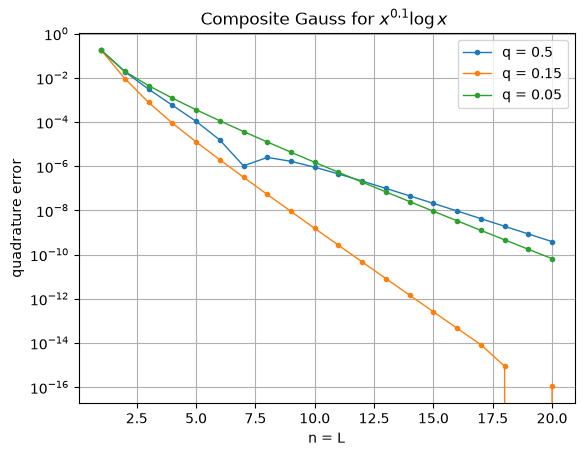

q =   0.5:  b = 0.934,  C = 2.018e-02
q =  0.15:  b = 1.864,  C = 2.424e-01
q =  0.05:  b = 1.089,  C = 1.149e-01


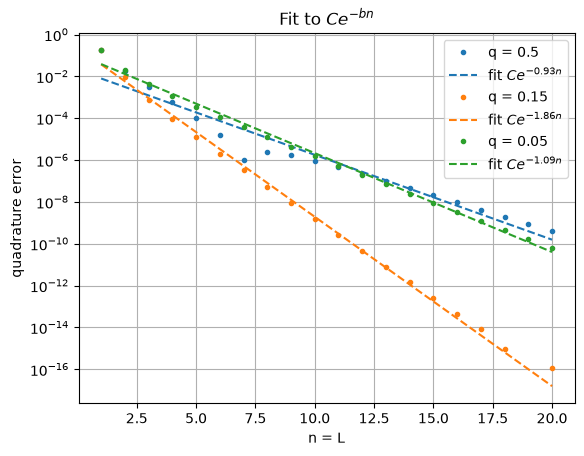

In [64]:
# b)
g = lambda x: x**0.1 * np.log(x)
exact_g = -1 / 1.1**2

n_vals = np.arange(1, 21)
q_vals = [0.5, 0.15, 0.05]

errors = {}
for q in q_vals:
    errors[q] = np.array([abs(composite_gauss(g, n, n, q) - exact_g) for n in n_vals])

plt.figure()
for q in q_vals:
    plt.semilogy(n_vals, errors[q], ".-", lw=1, label=f"q = {q}")
plt.xlabel("n = L")
plt.ylabel("quadrature error")
plt.title(r"Composite Gauss for $x^{0.1}\log x$ ")
plt.grid(True, which="both")
plt.legend()
plt.show()

# c)
tol = 1e-14 # exclude machine-precision 0s which would break the polyfit below!
plt.figure()
for q in q_vals:
    mask = errors[q] > tol
    slope, intercept = np.polyfit(n_vals[mask], np.log(errors[q][mask]), 1)
    b, C = -slope, np.exp(intercept)
    print(f"q = {q:>5}:  b = {b:.3f},  C = {C:.3e}")

    line, = plt.semilogy(n_vals, errors[q], ".", label=f"q = {q}")
    plt.semilogy(n_vals, C * np.exp(-b * n_vals), "--", color=line.get_color(),
                 label=rf"fit $C e^{{-{b:.2f} n}}$")
plt.xlabel("n = L")
plt.ylabel("quadrature error")
plt.title(r"Fit to $C e^{-bn}$")
plt.grid(True, which="both")
plt.legend()
plt.show()

Small $q$ >>> the piece/intervall containing the singularity (in terms of the derivative) shrinks fast, so its error doesnt matter as much; but every other interval spans the remaining steep and flat behaviour of $f$ at once, so Gauss is inaccurate on all of them smaller intervals. And also the last interval is very large, so the error there is also big.

Large $q$ >>> the opposite.
$q \approx 0.15$ balances both here

## 6.3
On paper

## 6.4

In [80]:
# composite rules from last exercise
def comp_trap_rule(f: callable, a: float, b:float, N: int = 1):
    """
        Realization of the composite trapezoidal rule for integration on [a,b]

        f: some function handle
        N: number of subintervals
        a, b: integration interval
    """

    h = (b - a) / N
    t = a + np.arange(1, N) * h   # interior nodes x_1, ..., x_{N-1}
    return h * (f(a)/2 + np.sum(f(t)) + f(b)/2)

def comp_simpson_rule(f: callable, a: float, b: float, N: int = 1):
    """
        Composite Simpson rule on [a,b]

        f: some function handle
        N: number of subintervals (each with its own midpoint)
        a, b: integration interval
    """
    h = (b - a) / N
    x = a + np.arange(N + 1) * h      # nodes x_0, ..., x_N
    m = x[:-1] + h / 2                # midpoints m_0, ..., m_{N-1}
    return h / 6 * (f(a) + 2 * np.sum(f(x[1:-1])) + 4 * np.sum(f(m)) + f(b))

def adapt(f, a, b, tau, h_min, rho = 0.5):
    m = (a + b) / 2
    S = comp_simpson_rule(f, a, b)
    S_fine = comp_simpson_rule(f, a, m) + comp_simpson_rule(f, m, b)

    if b-a <= h_min: 
        return S_fine
    elif np.abs(S - S_fine) <= tau * rho:
        return S_fine
    else:
        return adapt(f, a, m, tau/2, h_min, rho) + adapt(f, m, b, tau/2, h_min, rho)

In [81]:
# 6.4a) Just to double-check my handwritten solution
v = lambda x: x**2 * (x - 0.5)**2 * (x-1)**2
a, b = 0, 1

print("Simpson Rule:", comp_simpson_rule(v, a, b, 1))
print("Trapezoidal Rule:", comp_trap_rule(v, a, b, 1))

Simpson Rule: 0.0
Trapezoidal Rule: 0.0


Define the two test functions (step function with np.where, and lambda x: x**0.3) and their exact integrals $\frac23$ and $\frac1{1.3}$.

Loop over $j = 0,\dots,10$ with tau = h_min = 2.0^{-j}, and store the errors.

Plot error vs. $\tau$ in loglog (add a reference line $\tau$ for comparison).

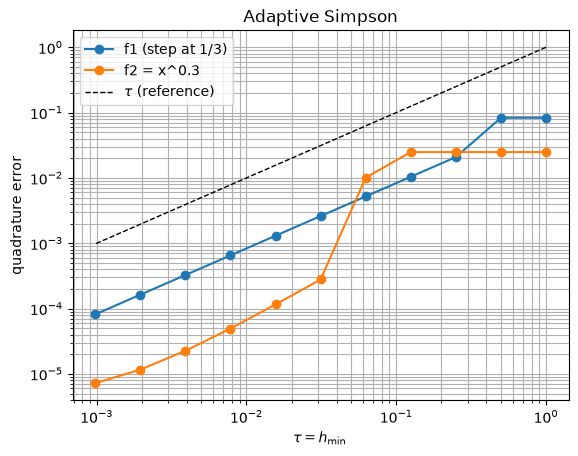

In [ ]:
f1 = lambda x: np.where(x < 1/3, 0.0, 1.0)
f2 = lambda x: x**0.3

funcs = {"f1 (step at 1/3)": (f1, 2/3),
         "f2 = x^0.3": (f2, 1/1.3)}

J = np.arange(0, 11)
taus = 2.0**(-J)

errors = {name: np.zeros(len(J)) for name in funcs}
for name, (f, exact) in funcs.items():
    for i, tau in enumerate(taus):
        errors[name][i] = abs(adapt(f, 0, 1, tau=tau, h_min=tau) - exact)

plt.figure()
for name in funcs:
    plt.loglog(taus, errors[name], "o-", label=name)
plt.loglog(taus, taus, "k--", lw=1, label=r"$\tau$ (reference)")
plt.xlabel(r"$\tau = h_{\min}$")
plt.ylabel("quadrature error")
plt.title("Adaptive Simpson")
plt.grid(True, which="both")
plt.legend()
plt.show()

Here we do not have an issue with the singularity directly, since there is exactly one interal that contains the jump (1/3 is no bisection point here, since we have the k/2**j). This jump of 1 inside this interval of length h will lead to a constant error that is dependent on this interval and so roughly $c\cdot h$. The local tolerance at the same depth is $\rho\,\tau\cdot h$ (it halves each time the interval halves). So the comparison is never really reached, since the error is always bigger than the tolerance. The error will be reduced by the bisection, but the tolerance will also be reduced by the same factor, so we will never reach a point where the error is smaller than the tolerance. 

$$c\cdot h \;\le\; \rho\,\tau\, h \quad\Longleftrightarrow\quad c \le \rho\,\tau.$$

Without $h_{\min}$ it would never stop, so choosing $h_{\min} = \tau$ makes that forced error the same order as the tolerance we were asked for. That’s why we see error $\sim \tau$ for f1 (the step function).

For f2 the error also behaves like: error $\sim \tau$, simply because that is our stopping criterion. The error is always smaller than the tolerance, so we stop when the tolerance is small enough. So with increasing $\tau$ we also get bigger erros


## 6.5

In [86]:
def midpoint2d_rule(f: callable, a: float, b: float, c: float, d: float):
    """
        midpoint 2d rule on [a,b] x [c, d]

        f: some function handle
        a, b, c, d: integration interval
    """
    h = (b - a) * (d - c)
    return h * f((a+b)/2, (c+d)/2)

def adapt(f, a, b, c, d, tau, h_min, rho = 0.5):
    m1 = (a + b) / 2   # midpoint in x
    m2 = (c + d) / 2   # midpoint in y

    S_base = midpoint2d_rule(f, a, b, c, d)
    S_fine = (midpoint2d_rule(f, a,  m1, c,  m2)    # lower left
            + midpoint2d_rule(f, m1, b,  c,  m2)    # lower right
            + midpoint2d_rule(f, a,  m1, m2, d )    # upper left
            + midpoint2d_rule(f, m1, b,  m2, d ))   # upper right

    if max(b - a, d - c) <= h_min:
        return S_fine
    elif np.abs(S_base - S_fine) <= tau * rho:
        return S_fine
    else:
        return adapt(f, a, m1, c, m2, tau/4, h_min, rho) + \
            adapt(f, m1, b, c, m2, tau/4, h_min, rho) + \
            adapt(f, a, m1, m2, d, tau/4, h_min, rho) + \
            adapt(f, m1, b, m2, d, tau/4, h_min, rho)

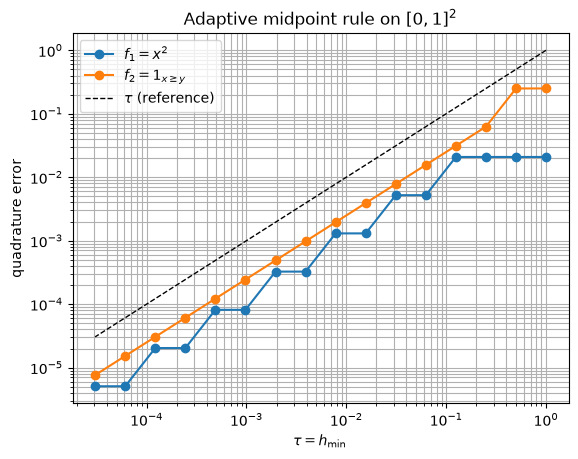

In [87]:
f1 = lambda x, y: x**2
f2 = lambda x, y: 1.0 if x >= y else 0.0

funcs = {r"$f_1 = x^2$":           (f1, 1/3),
         r"$f_2 = 1_{x \geq y}$":  (f2, 1/2)}

I = np.arange(0, 16)
taus = 2.0**(-I)

errors = {name: np.zeros(len(I)) for name in funcs}
for name, (f, exact) in funcs.items():
    for k, tau in enumerate(taus):
        errors[name][k] = abs(adapt(f, 0, 1, 0, 1, tau=tau, h_min=tau) - exact)

plt.figure()
for name in funcs:
    plt.loglog(taus, errors[name], "o-", label=name)
plt.loglog(taus, taus, "k--", lw=1, label=r"$\tau$ (reference)")
plt.xlabel(r"$\tau = h_{\min}$")
plt.ylabel("quadrature error")
plt.title(r"Adaptive midpoint rule on $[0,1]^2$")
plt.grid(True, which="both")
plt.legend()
plt.show()